# Содержание

1. [Подготовка данных для обучения](#s1)

2. [Класс ModelEvaluator](#s2)

3. [Обучение моделей](#s3)
     
4. [Вывод](#s4)

<div style="border:solid purple 5px; padding: 20px"> 


<b>Цель проекта</b>

<hr>
Создать систему раннего оповещения о развитии аварийных режимов водно-химического режима котла, основанную на анализе многомерных временных рядов с дифференциацией типов уноса для выбора корректной корректирующей стратегии.

<hr>
    
В данной тетради проводится  <b> проверка наличия глобальной закономерности  в данных технологического процесса с помощью простых моделей. </b>

**df_train.csv** - датасет для обучения моделей. 
       
<hr>

</div>  

Тип уноса:

- 0: 'Кислый унос (хлоридный)' 
- 1: 'Натриевый унос (щелочной)' 
- 2: 'Норма' 
- 3: 'Переходный режим'

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.model_selection import StratifiedGroupKFold

In [5]:
from sklearn.compose import ColumnTransformer

In [6]:
from sklearn.preprocessing import StandardScaler, RobustScaler

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [8]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.metrics import roc_curve, auc, confusion_matrix

In [9]:
from sklearn.utils.class_weight import compute_sample_weight

In [10]:
from sklearn.preprocessing import LabelBinarizer

In [11]:
# Снимаем ограничение на количество отображаемых столбцов
pd.set_option('display.max_columns', None)

## <a id="s1"></a> 1. Подготовка данных для обучения

In [12]:
train = pd.read_csv('df_train.csv', index_col ='data_time', parse_dates=[0])

In [13]:
train.head(2)

,hal40cf001,lba10cq201,had10cl001,hah90ct001,hha10cp001,had10cp001,lba10cf001,lba08cp001,hour_sin,hour_cos,dow_sin,dow_cos,lba10cq201_mean_2h,lba10cq201_std_2h,lba10cq201_std_4h,lba10cq201_delta_1,lba10cq201_delta_2,lba10cq201_delta_3,lba10cq201__accel,unos_type,group_id
data_time,,,,,,,,,,,,,,,,,,,,,
2017-01-01 07:00:00,0.528895,9.179148,-9.612786,521.836548,-4.428509,104.340546,174.140381,96.984283,0.965926,-0.258819,-0.781831,0.62349,9.261284,0.026110,0.042371,-0.100598,-0.063673,-0.000073,-0.137523,2,1
2017-01-01 08:00:00,0.503179,9.119442,-9.361613,523.308228,-4.457798,104.853897,173.366608,97.536438,0.866025,-0.500000,-0.781831,0.62349,9.229447,0.071133,0.049739,-0.059706,-0.160304,-0.123379,0.040892,2,1


In [14]:
features = train.copy()
features.drop(['group_id','unos_type'], axis=1, inplace=True)
target = train['unos_type']
groups = train['group_id']

In [15]:
groups.unique()

array([ 1,  3,  5,  7,  9, 11, 15, 17])

Для проверки наличия глобальной закономерности обучим простые модели. Для упрощения сделаем разбиение вручную: на группах 1, 3, 5, 7, 9 обучим модель, проверим на 11, 15 и 17 группах.

In [16]:
train_groups = [1, 3, 5, 7, 9] 
valid_groups = [11, 15, 17]

train_idx = groups[groups.isin(train_groups)].index
valid_idx = groups[groups.isin(valid_groups)].index

features_train, features_valid = features.loc[train_idx], features.loc[valid_idx]
target_train, target_valid = target.loc[train_idx], target.loc[valid_idx]

print(f"\nРазмер обучающей выборки: {features_train.shape}")
print(f"Размер валидационной выборки: {features_valid.shape}")
print(f"\nКлассы в обучающей выборке:\n {target_train.value_counts()}")
print(f"\nКлассы в валидационной выборки:\n {target_valid.value_counts()}")


Размер обучающей выборки: (4153, 19)
Размер валидационной выборки: (615, 19)

Классы в обучающей выборке:
 unos_type
2    1802
0    1269
1     732
3     350
Name: count, dtype: int64

Классы в валидационной выборки:
 unos_type
0    290
3    154
2    125
1     46
Name: count, dtype: int64


Линейные модели чувствительны к масштабам параметров, поэтому масштабируем признаки перед тем, как передать их в наши модели.

In [17]:
measured_parameters = ['hal40cf001', 'lba10cq201', 'had10cl001', 'hah90ct001', 'hha10cp001',
                      'had10cp001', 'lba10cf001', 'lba08cp001']
selected_parameters = [ 'lba10cq201_mean_2h', 'lba10cq201_std_2h', 'lba10cq201_std_4h',
                       'lba10cq201_delta_1', 'lba10cq201_delta_2',
                       'lba10cq201_delta_3', 'lba10cq201__accel']

preprocessor = ColumnTransformer([
        ('measur', StandardScaler(), measured_parameters),
        ('diffs', RobustScaler(), selected_parameters)
    ], remainder='passthrough')

In [18]:
preprocessor.fit(features_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('measur', ...), ('diffs', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

Стандартизируем параметры в наших выборках

In [19]:
features_train_transformed = preprocessor.transform(features_train)
features_valid_transformed = preprocessor.transform(features_valid)

feature_names = features_train.columns

features_train_transformed = pd.DataFrame(features_train_transformed, columns=feature_names, index=features_train.index)
features_valid_transformed = pd.DataFrame(features_valid_transformed, columns=feature_names, index=features_valid.index)

## <a id="s2"></a> 2.  Класс ModelEvaluator

In [20]:
class ModelEvaluator:
    def __init__(self, feature_train, feature_valid, target_train, target_valid):

        self.feature_train = feature_train
        self.feature_valid = feature_valid
        self.target_train = target_train
        self.target_valid = target_valid
        self.results = {}
        self.classes = np.unique(target_valid)
        self.class_names = ['0: Кислый унос', '1: Натриевый унос', '2: Норма', '3: Переходный режим']
   
    
    def _plot_roc_curves(self, name, model, proba_valid):
        """
        Построение ROC-кривых для каждого класса
        """
        plt.figure(figsize=(6, 4))
        lb = LabelBinarizer()
        target_bin = lb.fit_transform(self.target_valid)
        for i in range(len(self.classes)):
            fpr, tpr, _ = roc_curve(target_bin[:, i], proba_valid[:, i])
            roc_auc_value = auc(fpr, tpr)
            plt.plot(fpr, tpr, lw=2, label=f'Класс {i} (AUC = {roc_auc_value:.3f})')
        plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Случайный классификатор (AUC = 0.5)')

        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'ROC-кривые для каждого класса ({name})')
        plt.legend(loc="lower right")
        plt.grid(True, alpha=0.3)
        plt.show()

    def _plot_confusion_matrix(self, name, pred_valid):
        """
        Построение матрицы ошибок
        """
        plt.figure(figsize=(4,4))
        cm = confusion_matrix(self.target_valid, pred_valid)

        n_classes = len(self.classes)
        yticklabels = self.class_names[:n_classes if n_classes <=4 else [str(i) for i in range(n_classes)]]
        xticklabels = [str(i) for i in range(n_classes)] 
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   yticklabels=yticklabels,
                   xticklabels=xticklabels,
                   cbar_kws={'shrink':0.8})
        plt.xlabel('Истинный класс')
        plt.ylabel('Предсказанный класс')
        plt.title(f'Confusion Matrix - {name}')
        plt.show()

    def top_coef_lr(self, model, number_class=[0]):
        """
        Вывод признаков LogisticRegression
        в переменной number_class перечислите необходимые классы
        """
        feature_names = features_train.columns
        coefs = model.coef_  
        for i in number_class:
            class_coefs = pd.DataFrame({
                'feature': feature_names,
                'coefficient': coefs[i]
            })
            class_coefs['coeff_abs'] =  class_coefs['coefficient'].abs() 
            class_coefs = class_coefs.sort_values('coeff_abs', ascending=False).drop(columns='coeff_abs')
            print(f"\nТоп-10 признаков для класса {i}\n")
            print(class_coefs.head(10))

    def top_coef_trees(self, name, model, top=10):
        """
        Вывод важных признаков для RandomForest
        """
        feature_importance = pd.DataFrame({
            'feature': features_train.columns,
            'importance': model.feature_importances_
        }).sort_values('importance', ascending=False)

        print(f"\nТоп-{top} важнейших признаков для {name}:")
        print(feature_importance.head(top))


    def evaluation_model(self, name, model, plot_roc=True, plot_cm=True):
        print(f'\nОценка {name}')
        print('='*60)

        pred_valid = model.predict(self.feature_valid)
        
        proba_valid = None
        if hasattr(model,'predict_proba'):
            proba_valid = model.predict_proba(self.feature_valid)

        acc = accuracy_score(self.target_valid, pred_valid)
        #zero_division=0 - добавлен параметр, если деление на 0
        f1_macro = f1_score(self.target_valid, pred_valid, average='macro', zero_division=0) 
        f1_weighted = f1_score(self.target_valid, pred_valid, average='weighted', zero_division=0)

        if proba_valid is not None:
            auc_value = roc_auc_score(self.target_valid, proba_valid, multi_class='ovr', average='weighted')
        else:
            auc_value = None

        metrics = {
            'accuracy': acc,
            'f1_macro': f1_macro,
            'f1_weighted': f1_weighted,
            'roc_auc': auc_value,
            'model': model,
            'predictions': pred_valid,
            'probabilities': proba_valid
        } 

        print(f"  Accuracy:  {acc:.4f}")
        print(f"  F1-Score (macro):  {f1_macro:.4f}")
        print(f"  F1-Score (weighted):  {f1_weighted:.4f}")
        if auc_value is not None:
            print(f"  ROC-AUC:   {auc_value:.4f}")
        
        # Визуализация
        if name =='DummyClassifier':
            plot_roc = plot_cm = False
            
        if plot_roc and proba_valid is not None:
            self._plot_roc_curves(name, model, proba_valid)
        
        if plot_cm:
            self._plot_confusion_matrix(name, pred_valid)
        
        return metrics

    def run_evaluation_test(self, models, plot_roc=True, plot_cm=True):
        for name, model in models.items():
            model.fit(self.feature_train, self.target_train)
            metrics = self.evaluation_model(name, model, plot_roc, plot_cm)
            self.results[name] = metrics

            if name=='DummyClassifier':
                continue
            elif name=='LogisticRegression':
                self.top_coef_lr(model)
                
            else:
                self.top_coef_trees(name, model)
            
            print('-'*40)
        
        print(f"\nОценка завершена. Всего моделей: {len(models)}")
        return self.results

    def print_summary(self):
        """
        Вывод сводной таблицы результатов
        """
        if not self.results:
            print("Нет результатов. Сначала запустите run_evaluation_XXX ")
            return
        
        print("\n" + "="*60)
        print("Сводная таблица результатов")
        
        rows = []
        for name, m in self.results.items():
            rows.append({
                'Модель': name,
                'Accuracy': round(m['accuracy'], 4),
                'F1-macro': round(m['f1_macro'], 4),
                'F1-weighted': round(m['f1_weighted'], 4),
                 'ROC-AUC': round(m['roc_auc'], 4) if m['roc_auc'] is not None else None,
             })
        df = pd.DataFrame(rows).set_index('Модель')
        df = df.sort_values('F1-macro', ascending=False)
        display(df)

## <a id="s3"></a> 3. Обучение моделей


Оценка DummyClassifier
  Accuracy:  0.2033
  F1-Score (macro):  0.0845
  F1-Score (weighted):  0.0687
  ROC-AUC:   0.5000

Оценка LogisticRegression
  Accuracy:  0.5659
  F1-Score (macro):  0.3872
  F1-Score (weighted):  0.5592
  ROC-AUC:   0.8874


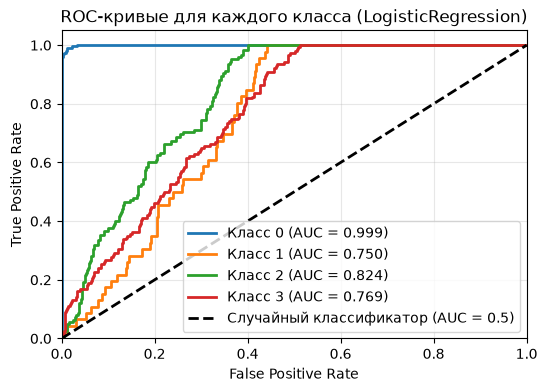

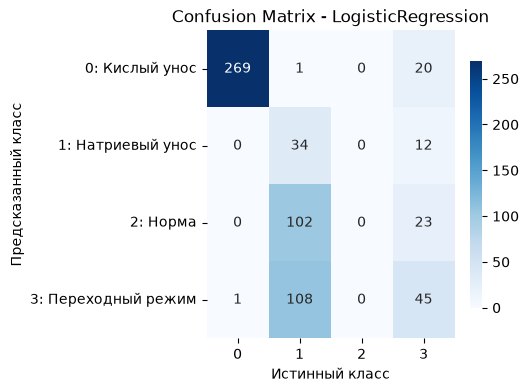


Топ-10 признаков для класса 0

               feature  coefficient
1           lba10cq201    -5.433430
8             hour_sin    -2.844695
10             dow_sin     0.687848
3           hah90ct001    -0.402161
6           lba10cf001     0.191969
12  lba10cq201_mean_2h    -0.175202
18   lba10cq201__accel    -0.147810
2           had10cl001     0.111965
0           hal40cf001     0.108205
15  lba10cq201_delta_1    -0.089123
----------------------------------------

Оценка RandomForest
  Accuracy:  0.6244
  F1-Score (macro):  0.4653
  F1-Score (weighted):  0.6304
  ROC-AUC:   0.9157


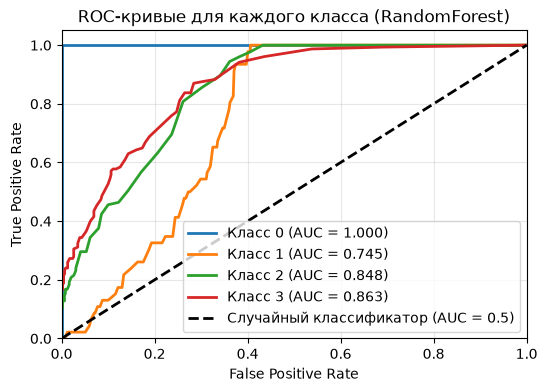

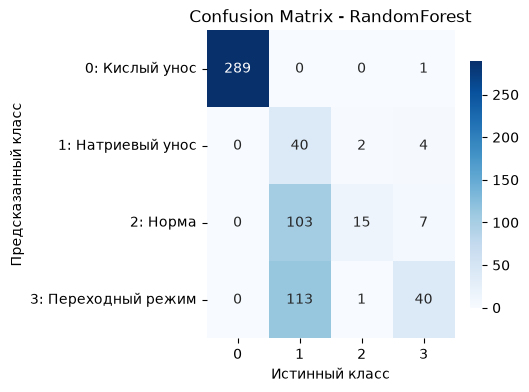


Топ-10 важнейших признаков для RandomForest:
               feature  importance
1           lba10cq201    0.270422
10             dow_sin    0.205455
8             hour_sin    0.181778
9             hour_cos    0.061824
13   lba10cq201_std_2h    0.040207
11             dow_cos    0.039223
6           lba10cf001    0.034160
12  lba10cq201_mean_2h    0.031302
2           had10cl001    0.029506
3           hah90ct001    0.020546
----------------------------------------

Оценка завершена. Всего моделей: 3

Сводная таблица результатов


,Accuracy,F1-macro,F1-weighted,ROC-AUC
Модель,,,,
RandomForest,0.6244,0.4653,0.6304,0.9157
LogisticRegression,0.5659,0.3872,0.5592,0.8874
DummyClassifier,0.2033,0.0845,0.0687,0.5000


In [21]:
evaluator = ModelEvaluator(
    features_train_transformed,
    features_valid_transformed,
    target_train,
    target_valid
)

models = {
    'DummyClassifier': DummyClassifier(strategy='most_frequent', random_state=12345),
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=12345, class_weight='balanced'),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=12345)
}

results = evaluator.run_evaluation_test(models, plot_roc=True, plot_cm=True) 
evaluator.print_summary()

## <a id="s4"></a> 4. Вывод

В рамках проверки наличия глобальной закономерности в данных технологического процесса проведен сравнительный анализ эффективности различных алгоритмов машинного обучения: 

- DummyClassifier, который всегда предсказывает наиболее частый класс;
- LogisticRegression - для оценки линейных связей;
- RandomForest — для проверки гипотезы о нелинейности процесса.

Наилучший результат показал Random Forest (Accuracy = 0.63, ROC-AUC = 0.9157).

Анализ матрицы ошибок и ROC-кривых показал, что модель демонстрирует идеальное детектирование класса 0 «Кислотный унос» (AUC = 1.00), что физически обосновано жесткой пороговой зависимостью данного режима от уровня pH. Это подтверждает надежность модели как инструмента аварийной сигнализации. 

Анализ важности признаков в модели Random Forest показал, что наибольший вклад в предсказание вносят lba10cq201 (27.04%), dow_sin (20.54%) и hour_sin (18.17%). Это указывает на то, что параметр pH и временные характеристики процесса являются ключевыми детерминантами типа уноса солей. Остальные признаки имеют суммарный вклад менее 35%.

Не смотря на то, что случайный лес ожидаемо превосходит линейную модель по обобщающей способности (ROC-AUC = 0.9157 против 0.8874), однако при детальном рассмотрении результатов по каждому классу выявлена существенная асимметрия в качестве предсказаний. Классы 2 («Норма») и 3 («Переходный режим») демонстрируют значительно более низкое качество распознавания. Как видно из матрицы ошибок (Random Forest), объекты класса 3 часто ошибочно классифицируются как класс 1 («Натриевый унос»): 113 наблюдений из 154 были неверно отнесены к классу 1. Класс 2 также показывает низкую точность: только 15 из 125 объектов распознаны верно, при этом основная масса (103 объекта) ошибочно предсказана как класс 1. Это указывает на то, что границы между классами 2, 3 в пространстве признаков являются размытыми, имеют сложную нелинейную структуру, которую текущие модели не в состоянии полностью уловить. 

В связи с этим предлагаю обучить модели XGBoost и CatBoost для оценки их возможностей. В качестве оценочной метрики предлагаю использовать F1-macro. Это даст возможность лучше оценить баланс precision и recall для каждого класса.
